# Experiment 14: House Price Prediction
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Implement **House Price Prediction** using appropriate machine-learning algorithms.

## Note on the data
A **synthetic housing data set** (area, bedrooms, bathrooms, age, distance to city, locality rating, garage) is generated with a fixed seed so the notebook is self-contained. To use a real data set (e.g. Kaggle / California housing) replace the data cell with `df = pd.read_csv(...)` and set `target = '<price column>'`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(7)
n = 2000
area = rng.normal(1800, 600, n).clip(500, 4500).round()
bed = np.clip((area / 600 + rng.integers(-1, 2, n)).round(), 1, 6).astype(int)
bath = np.clip(bed - rng.integers(0, 2, n), 1, 5).astype(int)
age = rng.integers(0, 40, n)
dist = rng.uniform(1, 30, n).round(1)
rating = rng.integers(1, 11, n)
garage = rng.integers(0, 2, n)
price = (30 + 0.055 * area + 6 * bed + 4 * bath - 0.8 * age - 1.2 * dist + 5 * rating + 8 * garage
         + 0.00001 * area ** 2 + rng.normal(0, 12, n))          # price in lakhs
df = pd.DataFrame({'Area_sqft': area, 'Bedrooms': bed, 'Bathrooms': bath, 'Age_years': age,
                   'Dist_to_city_km': dist, 'Locality_rating': rating, 'Garage': garage,
                   'Price_Lakhs': price.round(2)})
df.to_csv('house_price_synthetic.csv', index=False)
print(df.shape)
df.head()

(2000, 8)


,Area_sqft,Bedrooms,Bathrooms,Age_years,Dist_to_city_km,Locality_rating,Garage,Price_Lakhs
0,1801.0,4,4,11,10.8,6,1,235.81
1,1979.0,3,2,1,26.7,7,0,209.86
2,1636.0,3,2,0,22.9,7,1,202.47
3,1266.0,3,3,35,1.5,6,0,146.76
4,1527.0,3,3,32,19.2,6,0,130.49


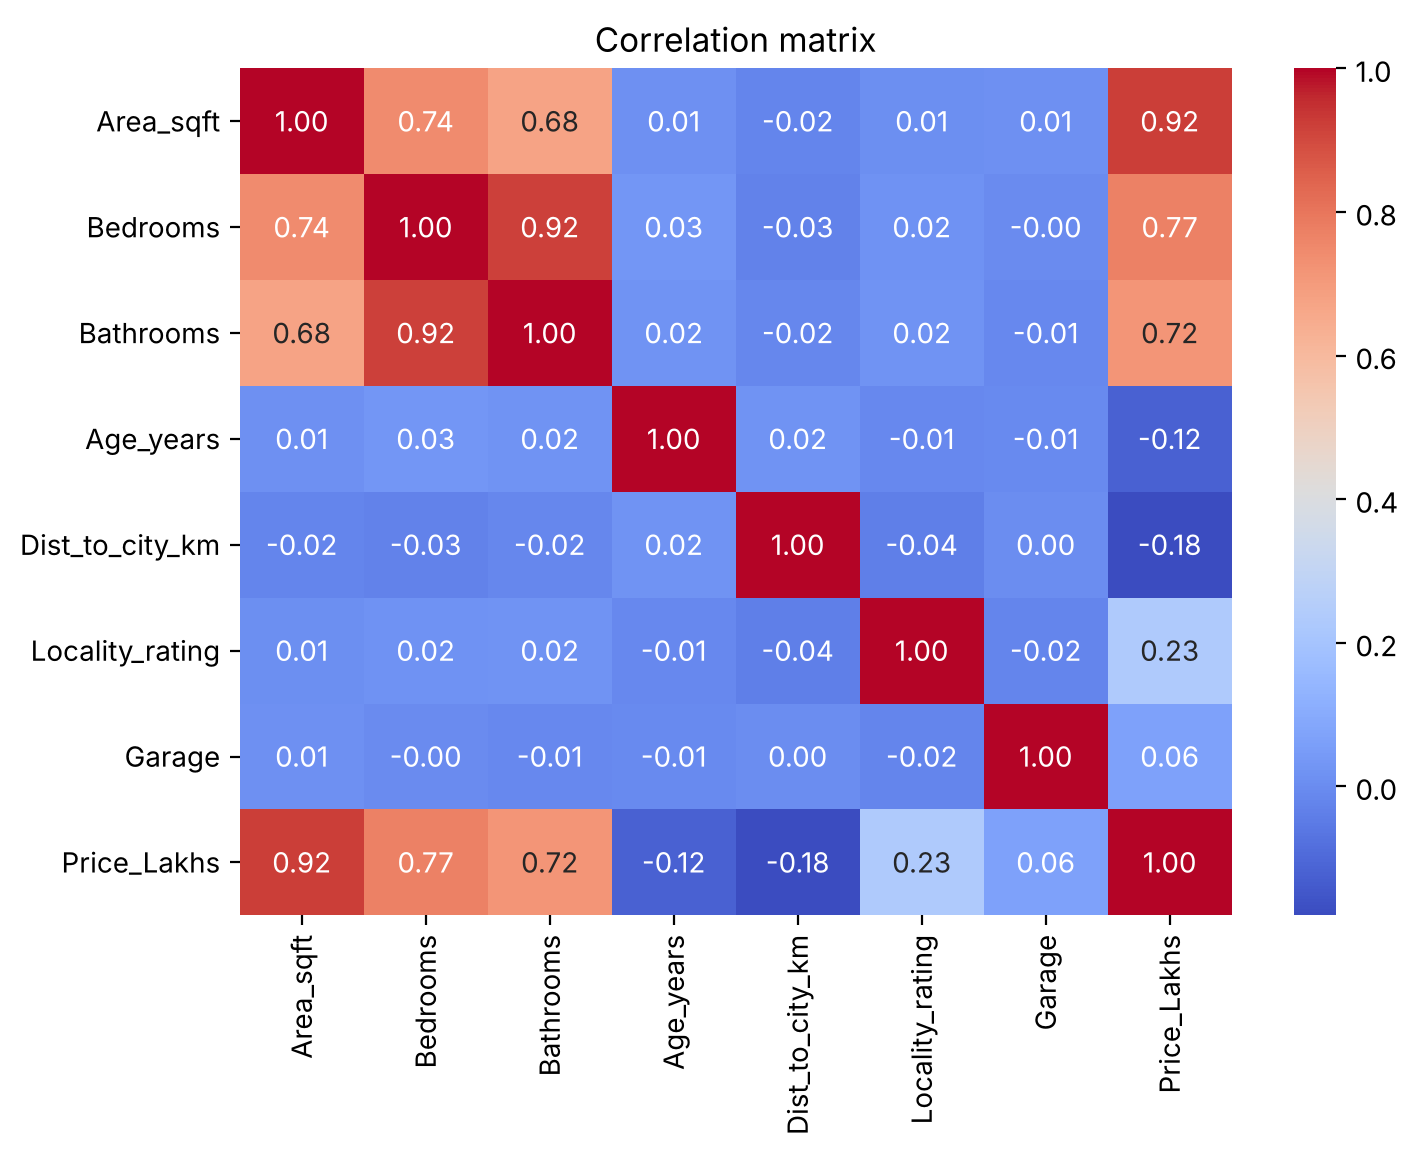

In [2]:
plt.figure(figsize=(8, 5.5))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation matrix'); plt.show()

In [3]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

target = 'Price_Lakhs'
X, y = df.drop(columns=target), df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
    'Ridge Regression': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'Decision Tree': DecisionTreeRegressor(max_depth=6, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
}
rows = []
for name, m in models.items():
    m.fit(X_train, y_train); p = m.predict(X_test)
    rows.append({'Model': name, 'R2': r2_score(y_test, p), 'MAE': mean_absolute_error(y_test, p),
                 'RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'CV R2 (5-fold)': cross_val_score(m, X, y, cv=5, scoring='r2').mean()})
results = pd.DataFrame(rows).round(4).sort_values('R2', ascending=False)
results

,Model,R2,MAE,RMSE,CV R2 (5-fold)
0,Linear Regression,0.9664,9.9303,12.2799,0.9627
1,Ridge Regression,0.9663,9.9333,12.2851,0.9627
4,Gradient Boosting,0.9581,10.8854,13.7090,0.9585
3,Random Forest,0.9517,11.6953,14.7159,0.9495
2,Decision Tree,0.8957,17.3161,21.6221,0.9050


Best model: Linear Regression


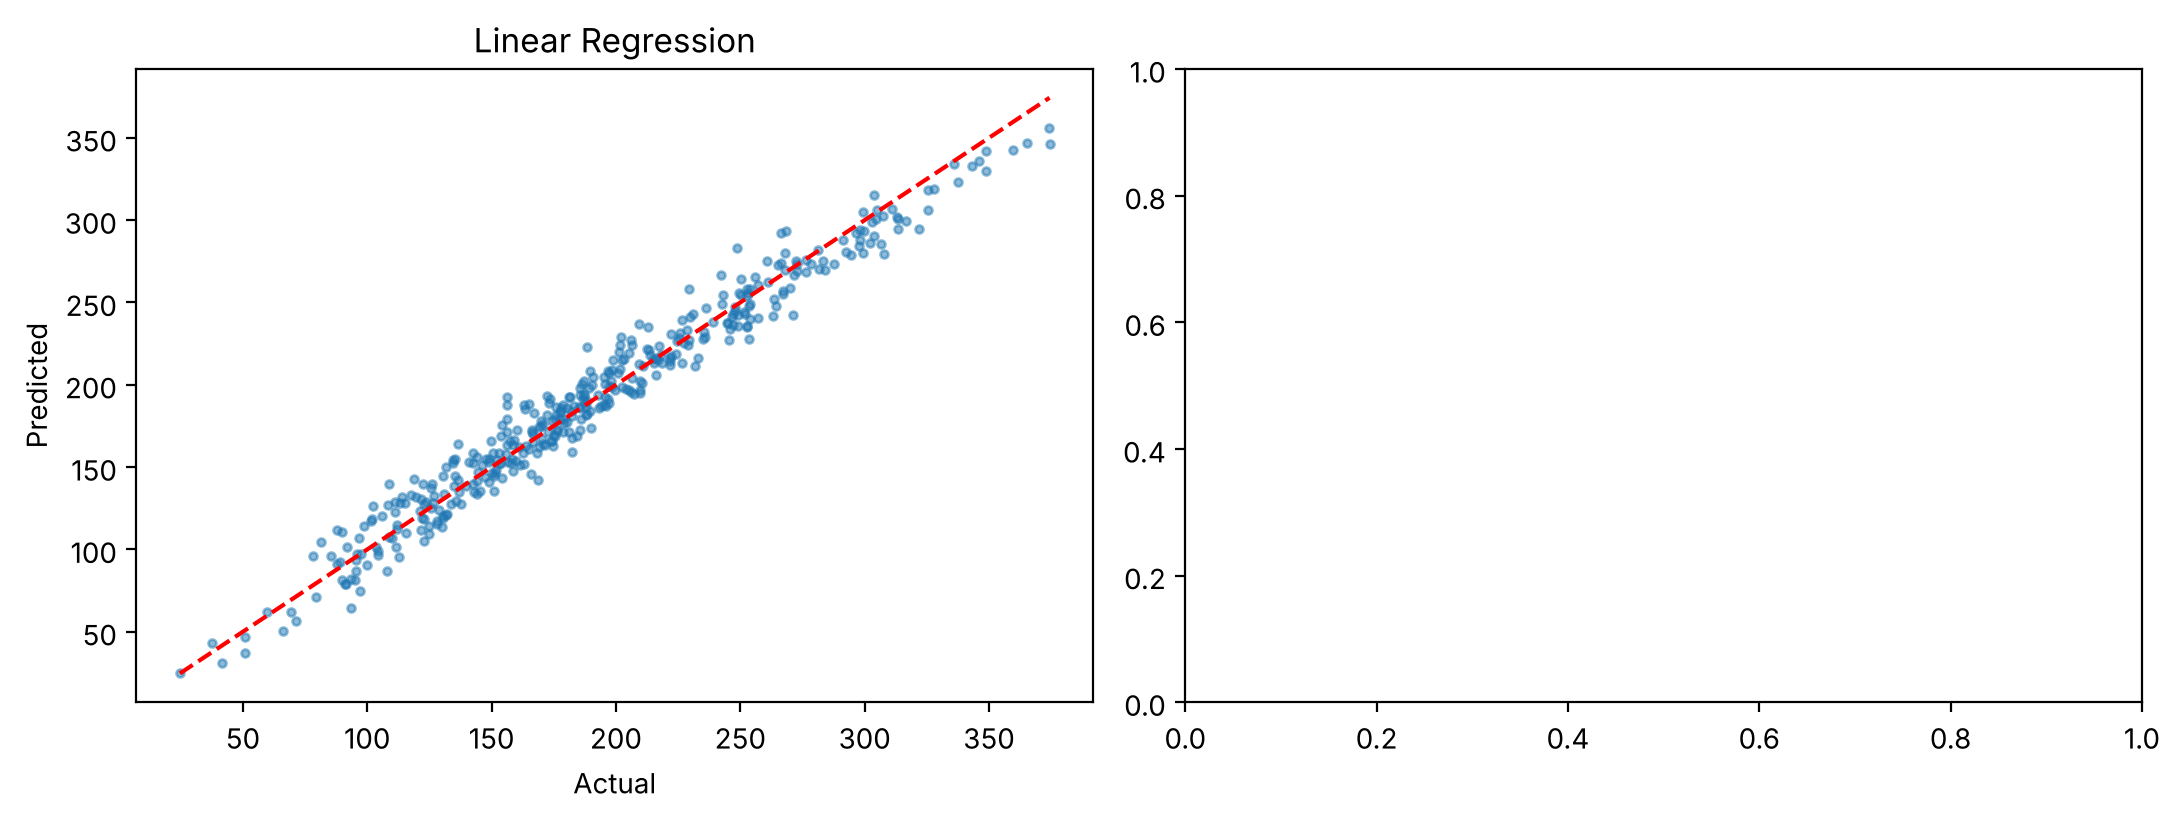

Predicted price for the new house: 243.42 Lakhs


In [4]:
best_name = results.iloc[0]['Model']
best = models[best_name]
pred = best.predict(X_test)
print('Best model:', best_name)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].scatter(y_test, pred, s=8, alpha=0.5)
lim = [y_test.min(), y_test.max()]; ax[0].plot(lim, lim, 'r--')
ax[0].set_xlabel('Actual'); ax[0].set_ylabel('Predicted'); ax[0].set_title(f'{best_name}')
if hasattr(best, 'feature_importances_'):
    pd.Series(best.feature_importances_, index=X.columns).sort_values().plot.barh(ax=ax[1], color='teal')
    ax[1].set_title('Feature importance')
plt.tight_layout(); plt.show()

house = pd.DataFrame([{'Area_sqft': 2000, 'Bedrooms': 3, 'Bathrooms': 2, 'Age_years': 5,
                       'Dist_to_city_km': 8.0, 'Locality_rating': 8, 'Garage': 1}])
print(f'Predicted price for the new house: {best.predict(house)[0]:.2f} Lakhs')

## Result
Area, locality rating, distance to the city and age drive the price. Ensemble models and (for this roughly linear data) linear/ridge regression all perform well; the best model by test R2 was used to price a new house.